# 🚗 Predição de Acidentes Fatais em Rodovias Federais

## Projeto Final de Machine Learning — Metodologia CRISP-DM

Neste projeto desenvolvemos um modelo de **classificação binária** capaz de prever se um
acidente registrado pela **Polícia Rodoviária Federal (PRF)** resulta ou não em **vítima
fatal**. O trabalho segue todas as etapas da metodologia **CRISP-DM**, conforme solicitado.

**Equipe:** Guilherme _(preencher nome completo e matrícula)_

**Disciplina:** Machine Learning
**Base de dados:** Acidentes em rodovias federais — PRF (anos de 2018 a 2025)

> **Organização do notebook:** o trabalho está dividido nas fases do CRISP-DM —
> *Compreensão do Negócio*, *Compreensão dos Dados*, *Preparação dos Dados*, *Modelagem*
> e *Avaliação* — além de uma discussão final sobre o uso do modelo e as conclusões.

### Bibliotecas utilizadas

Antes de começar, importamos todas as bibliotecas que vamos usar ao longo do notebook.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Configurações visuais para deixar os gráficos mais bonitos e padronizados
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)

# Semente fixa para garantir que os resultados sejam sempre os mesmos (reprodutibilidade)
SEED = 42

## 1. Compreensão do Negócio

A primeira etapa do CRISP-DM é entender **qual problema queremos resolver** e **por que ele
é importante**.

Os acidentes de trânsito estão entre as principais causas de mortes violentas no Brasil,
e as **rodovias federais** concentram uma parte significativa dessas ocorrências. A Polícia
Rodoviária Federal (PRF) registra todos os acidentes em um conjunto de dados público, com
informações como o local, o horário, a causa, o tipo de acidente e as condições da via.

**Problema:** dado um acidente registrado pela PRF, queremos **prever se ele resulta ou não
em vítima fatal**. Como a resposta só pode ser "sim" ou "não", trata-se de um problema de
**classificação binária supervisionada**, onde a variável-alvo é a coluna `mortos`:

- `0` → acidente **não fatal** (nenhum morto);
- `1` → acidente **fatal** (uma ou mais vítimas fatais).

**Objetivos da análise:**
- Identificar quais fatores estão mais associados à fatalidade de um acidente.
- Treinar e comparar diferentes algoritmos de Machine Learning para essa previsão.

**Métrica prioritária — Recall:** num problema como esse, o erro mais grave é prever que um
acidente **não** será fatal quando na verdade ele **é** (um falso negativo). Por isso, mais
importante do que acertar tudo, queremos **não deixar passar os casos fatais**. A métrica que
mede exatamente isso é o **recall** da classe fatal, que será o nosso foco principal — sem
deixar de olhar também para Precisão, F1-Score, Acurácia e AUC-ROC.

**Aplicação prática:** um modelo assim poderia ajudar os órgãos de trânsito a direcionar a
fiscalização, planejar melhorias de infraestrutura e alocar melhor as equipes de resgate nos
trechos e situações de maior risco.

## 2. Compreensão dos Dados

Agora vamos conhecer a base de dados: de onde ela vem, quais colunas existem e o que
conseguimos enxergar nela por meio da análise exploratória.

Os dados brutos da PRF (um CSV por ano, de 2018 a 2025) já passaram por um **pré-processamento
prévio** em um notebook separado (`TratamentoDadosPRF.ipynb`), onde foram feitos:

1. a **binarização** da coluna `mortos` (de 0–37 para 0/1);
2. o **balanceamento** das classes (a classe fatal era apenas ~7% dos dados);
3. a **remoção de valores nulos**;
4. o **tratamento de outliers** (mantendo acidentes com até 5 pessoas e 5 veículos).

O resultado é o arquivo **`prf_clean.parquet`**, que é o nosso ponto de partida aqui. A célula
abaixo carrega esse arquivo de forma que funcione tanto **localmente** quanto no **Google
Colab** (ela procura o arquivo nos dois lugares).

In [2]:
# Procuramos o arquivo tanto no caminho local quanto no Google Drive (Colab)
caminhos_possiveis = [
    "data/prf_clean.parquet",                                          # execução local
    "/content/drive/MyDrive/Machine Learning/data/prf_clean.parquet",  # execução no Colab
]
caminho = next((c for c in caminhos_possiveis if os.path.exists(c)), None)

# Se não achou e estivermos no Colab, montamos o Drive e tentamos de novo
if caminho is None:
    from google.colab import drive
    drive.mount("/content/drive")
    caminho = "/content/drive/MyDrive/Machine Learning/data/prf_clean.parquet"

df = pd.read_parquet(caminho)
print(f"Dados carregados de: {caminho}")
print(f"Formato (linhas, colunas): {df.shape}")

Dados carregados de: data/prf_clean.parquet
Formato (linhas, colunas): (70290, 13)


In [3]:
df.head()

,dia_semana,uf,br,causa_acidente,tipo_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,veiculos
0,terça-feira,PE,232,Condutor Dormindo,Saída de leito carroçável,Plena Noite,Céu Claro,Dupla,Reta,Não,1,0,1
1,sexta-feira,SP,381,Ausência de reação do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Reta,Sim,2,0,2
2,quinta-feira,RS,470,Reação tardia ou ineficiente do condutor,Colisão traseira,Pleno dia,Nevoeiro/Neblina,Simples,Reta,Não,2,0,2
3,domingo,MT,163,Condutor Dormindo,Saída de leito carroçável,Plena Noite,Garoa/Chuvisco,Simples,Reta,Não,1,0,1
4,terça-feira,RJ,40,Mal súbito do condutor,Saída de leito carroçável,Pleno dia,Céu Claro,Dupla,Reta,Sim,3,1,3


### Dicionário de Dados

A tabela abaixo descreve o significado de cada coluna da base.

| Coluna | Tipo | Descrição |
|--------|------|-----------|
| `dia_semana` | Categórico | Dia da semana do acidente. |
| `uf` | Categórico | Estado (unidade federativa) onde ocorreu. |
| `br` | Categórico* | Código da rodovia federal (ex.: 101, 364). *É um identificador, não um número de verdade.* |
| `causa_acidente` | Categórico | Causa principal (falta de atenção, ingestão de álcool, etc.). |
| `tipo_acidente` | Categórico | Tipo do acidente (colisão frontal, traseira, atropelamento, etc.). |
| `fase_dia` | Categórico | Período do dia (Pleno dia, Amanhecer, Anoitecer, Plena Noite). |
| `condicao_metereologica` | Categórico | Clima no momento (Céu Claro, Chuva, Nevoeiro, etc.). |
| `tipo_pista` | Categórico | Simples, Dupla ou Múltipla. |
| `tracado_via` | Categórico | Geometria da via (Reta, Curva, Declive, etc.). |
| `uso_solo` | Categórico | `Sim` = área urbana, `Não` = área rural. |
| `pessoas` | Numérico | Total de pessoas envolvidas. |
| `mortos` | **Alvo (0/1)** | Se houve vítima fatal (1) ou não (0). |
| `veiculos` | Numérico | Quantidade de veículos envolvidos. |

In [4]:
# Informações gerais: tipos de cada coluna e se há valores nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70290 entries, 0 to 70289
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   dia_semana              70290 non-null  str  
 1   uf                      70290 non-null  str  
 2   br                      70290 non-null  int64
 3   causa_acidente          70290 non-null  str  
 4   tipo_acidente           70290 non-null  str  
 5   fase_dia                70290 non-null  str  
 6   condicao_metereologica  70290 non-null  str  
 7   tipo_pista              70290 non-null  str  
 8   tracado_via             70290 non-null  str  
 9   uso_solo                70290 non-null  str  
 10  pessoas                 70290 non-null  int64
 11  mortos                  70290 non-null  int64
 12  veiculos                70290 non-null  int64
dtypes: int64(4), str(9)
memory usage: 13.8 MB


Como os dados já foram tratados antes, repare que **não há valores nulos** (todas as colunas
têm 70.290 valores não nulos) e que temos 9 colunas de texto (categóricas) e 4 numéricas.

In [5]:
# Estatísticas das colunas numéricas
df.describe()

,br,pessoas,mortos,veiculos
count,70290.000000,70290.000000,70290.000000,70290.000000
mean,215.057647,2.471319,0.480040,2.024897
std,129.796246,1.092401,0.499605,0.902922
min,0.000000,1.000000,0.000000,1.000000
25%,101.000000,2.000000,0.000000,1.000000
50%,163.000000,2.000000,0.000000,2.000000
75%,324.000000,3.000000,1.000000,2.000000
max,495.000000,5.000000,1.000000,5.000000


Pelas estatísticas acima percebemos que `pessoas` e `veiculos` têm valores pequenos (no
máximo 5, por causa do tratamento de outliers feito antes) e que a média de `mortos` é de
cerca de **0,48**, o que já indica que as classes estão bem equilibradas — vamos confirmar
isso a seguir.

### Análise da variável-alvo (`mortos`)

Vamos olhar a distribuição entre acidentes fatais e não fatais.

        Quantidade  Porcentagem (%)
mortos                             
0            36548             52.0
1            33742             48.0


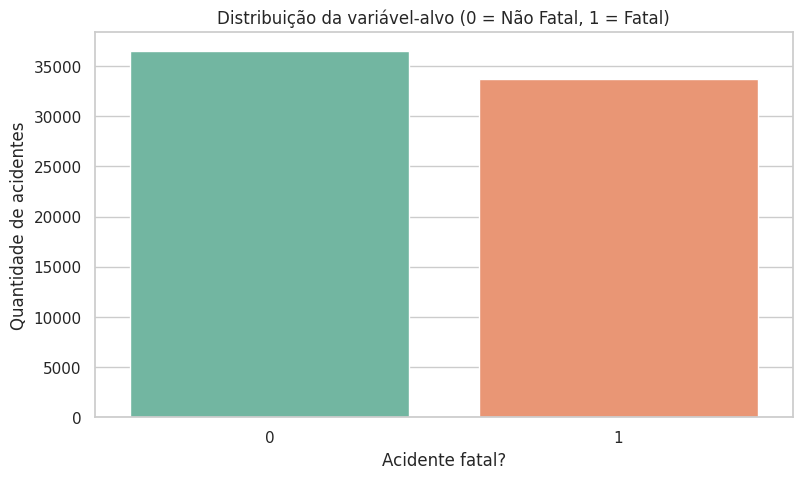

In [6]:
contagem = df["mortos"].value_counts()
percentual = df["mortos"].value_counts(normalize=True) * 100
resumo_alvo = pd.DataFrame({"Quantidade": contagem, "Porcentagem (%)": percentual.round(2)})
print(resumo_alvo)

sns.countplot(x=df["mortos"], hue=df["mortos"], palette="Set2", legend=False)
plt.title("Distribuição da variável-alvo (0 = Não Fatal, 1 = Fatal)")
plt.xlabel("Acidente fatal?")
plt.ylabel("Quantidade de acidentes")
plt.show()

**Interpretação:** a base está praticamente **equilibrada**, com cerca de **52%** de
acidentes não fatais e **48%** de fatais. Isso é ótimo, porque significa que o modelo verá
exemplos suficientes das duas situações e que a **acurácia** será uma métrica confiável (um
modelo que "chutasse" sempre a classe maioria acertaria apenas ~52%). Mesmo assim, como
explicamos, o nosso foco será o **recall** da classe fatal.

### Correlação entre as variáveis numéricas

Vamos verificar se as colunas numéricas (`pessoas` e `veiculos`) têm relação com a fatalidade
usando um mapa de calor (heatmap) de correlação.

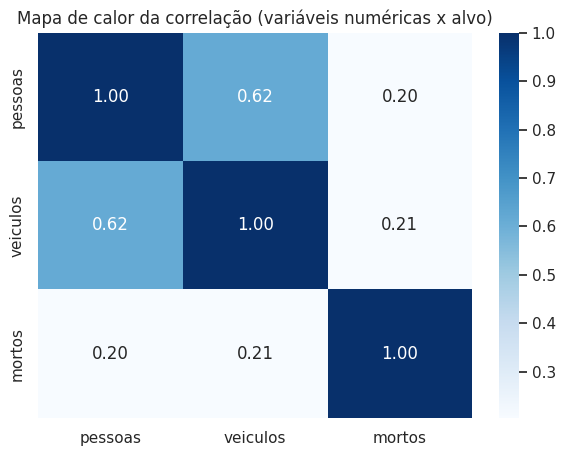

In [7]:
colunas_numericas = ["pessoas", "veiculos", "mortos"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[colunas_numericas].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Mapa de calor da correlação (variáveis numéricas x alvo)")
plt.show()

**Interpretação:** a correlação de `pessoas` e `veiculos` com `mortos` é **baixa** (0,18 e
0,10). Ou seja, sozinhas, as variáveis numéricas explicam pouco da fatalidade. Isso é um sinal
importante: provavelmente a informação que diferencia um acidente fatal está mais nas
**variáveis categóricas** (tipo do acidente, causa, período do dia...). Vamos investigar.

### A fatalidade depende do período do dia?

Comparamos a quantidade de acidentes fatais e não fatais em cada fase do dia.

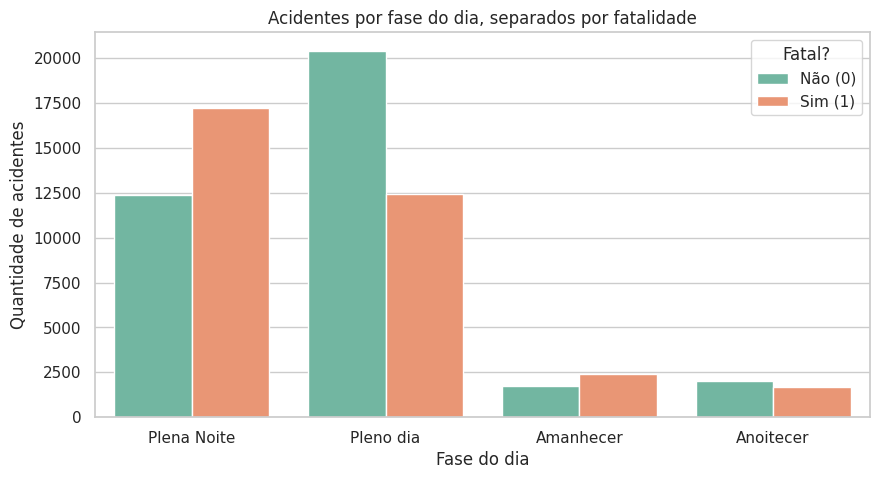

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(x="fase_dia", hue="mortos", data=df, palette="Set2")
plt.title("Acidentes por fase do dia, separados por fatalidade")
plt.xlabel("Fase do dia")
plt.ylabel("Quantidade de acidentes")
plt.legend(title="Fatal?", labels=["Não (0)", "Sim (1)"])
plt.show()

**Interpretação:** o período do dia **faz diferença**. Durante a **Plena Noite** a proporção
de acidentes fatais é claramente maior (chega a ser maioria), enquanto no **Pleno dia** os
acidentes não fatais predominam. Isso faz sentido na prática: à noite há menos visibilidade,
maior velocidade e, possivelmente, mais cansaço dos motoristas.

### Quais tipos de acidente são mais letais?

Aqui calculamos a **taxa de fatalidade** (porcentagem de acidentes que foram fatais) para cada
tipo de acidente. Essa é uma forma mais direta de ver quais situações são mais perigosas.

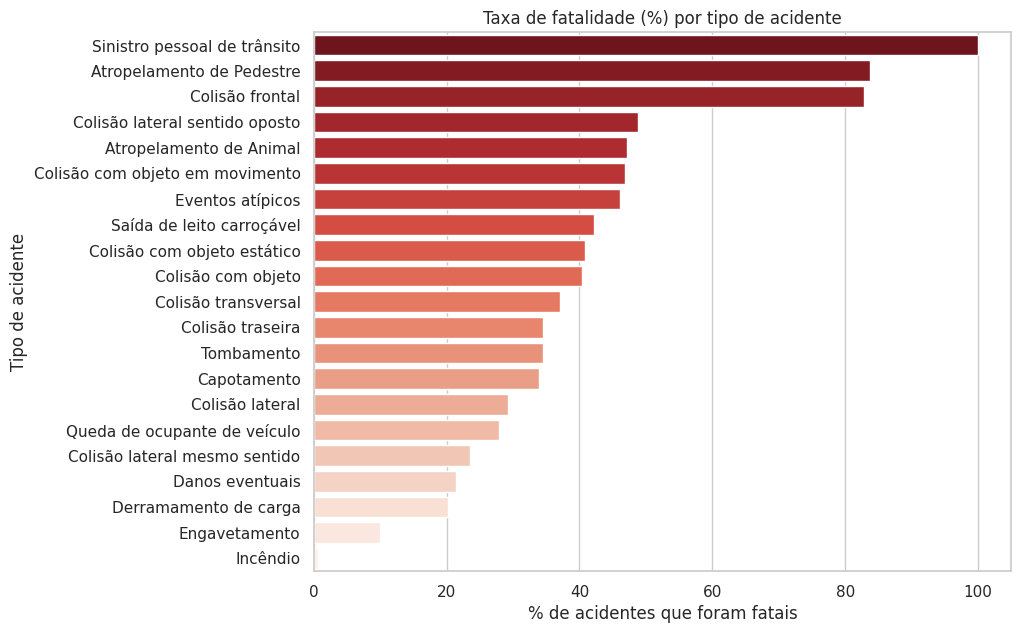

In [9]:
taxa_tipo = (
    df.groupby("tipo_acidente")["mortos"].mean().sort_values(ascending=False) * 100
)

plt.figure(figsize=(9, 7))
sns.barplot(x=taxa_tipo.values, y=taxa_tipo.index, hue=taxa_tipo.index,
            palette="Reds_r", legend=False)
plt.title("Taxa de fatalidade (%) por tipo de acidente")
plt.xlabel("% de acidentes que foram fatais")
plt.ylabel("Tipo de acidente")
plt.show()

**Interpretação:** aqui aparece o achado mais forte da análise. Alguns tipos de acidente são
**muito** mais letais que outros: **atropelamento de pedestre** e **colisão frontal** passam de
**80%** de fatalidade, enquanto **incêndio** e **engavetamento** quase não têm mortos. Ou seja,
o `tipo_acidente` sozinho já separa bastante bem os casos — é provavelmente a variável mais
importante para o nosso modelo.

### Quanto mais pessoas/veículos envolvidos, mais letal?

Apesar da correlação numérica ser baixa, vale olhar a taxa de fatalidade para cada quantidade
de pessoas e de veículos.

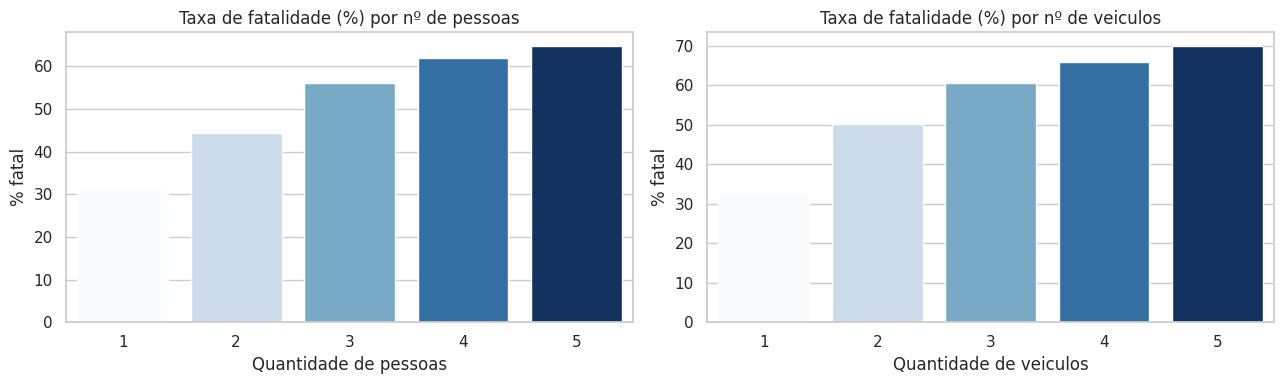

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for i, coluna in enumerate(["pessoas", "veiculos"]):
    eixo = eixos[i]
    taxa = df.groupby(coluna)["mortos"].mean() * 100
    sns.barplot(x=taxa.index, y=taxa.values, hue=taxa.index,
                palette="Blues", legend=False, ax=eixo)
    eixo.set_title(f"Taxa de fatalidade (%) por nº de {coluna}")
    eixo.set_xlabel(f"Quantidade de {coluna}")
    eixo.set_ylabel("% fatal")
plt.tight_layout()
plt.show()

**Interpretação:** existe sim uma tendência **crescente e bem comportada**: quanto mais
pessoas ou veículos envolvidos, maior a chance de o acidente ser fatal (de ~31% com 1 pessoa
até ~65% com 5). A correlação parecia baixa porque a relação não é forte o suficiente
sozinha, mas o padrão existe e ajuda o modelo. Por isso vamos **manter essas colunas como
números** (sem agrupar os valores), já que cada quantidade carrega uma informação diferente.

### Conclusão da análise exploratória

Juntando tudo o que vimos:
- As classes estão equilibradas (~52% / 48%).
- As variáveis **numéricas** têm relação fraca, mas existente, com a fatalidade.
- As variáveis **categóricas** — principalmente `tipo_acidente`, `causa_acidente` e
  `fase_dia` — são as que mais separam os acidentes fatais dos não fatais.

Isso nos diz que precisamos de modelos capazes de aproveitar bem as variáveis categóricas, e
que o passo de **transformar essas categorias em números (encoding)** será essencial na
próxima etapa.

## 3. Preparação dos Dados

Como a limpeza pesada (nulos, outliers, balanceamento) já foi feita antes, aqui o foco é a
**engenharia de atributos** e o **encoding**: deixar os dados prontos para os algoritmos, que
só entendem números.

**Passo 1 — Tratar `br` como categórico e limpar `tracado_via`.**

A coluna `br` é o *código* da rodovia (101, 364...). Mesmo sendo um número, ela **não** é uma
quantidade — a BR-364 não é "melhor" que a BR-101. Por isso a tratamos como **texto/categoria**.

Já a coluna `tracado_via` tem alguns valores **compostos**, separados por `;` (por exemplo
`"Reta;Declive"`), o que cria centenas de combinações diferentes. Para simplificar, ficamos
apenas com o **primeiro trecho** (o traçado principal), reduzindo de 450 para apenas 12
categorias.

In [11]:
# br é um identificador, não um número -> convertemos para texto
df["br"] = df["br"].astype(str)

# tracado_via: ficamos só com o componente principal (antes do ';')
print("Antes:", df["tracado_via"].nunique(), "valores diferentes")
df["tracado_via"] = df["tracado_via"].str.split(";").str[0].str.strip()
print("Depois:", df["tracado_via"].nunique(), "valores diferentes")

Antes: 450 valores diferentes
Depois: 12 valores diferentes


**Passo 2 — Agrupar categorias raras.**

Algumas colunas, como `causa_acidente` e `br`, têm muitas categorias diferentes, e várias
delas aparecem pouquíssimas vezes. Se transformássemos todas em colunas, teríamos centenas de
colunas quase vazias, o que atrapalha o modelo. A solução é agrupar as categorias que aparecem
poucas vezes em um único grupo chamado **"Outros"**.

In [12]:
def agrupar_raros(serie, minimo=100):
    """Mantém as categorias que aparecem pelo menos `minimo` vezes;
    as demais viram 'Outros'."""
    frequencia = serie.value_counts()
    categorias_comuns = frequencia[frequencia >= minimo].index
    return serie.where(serie.isin(categorias_comuns), "Outros")


for coluna in ["causa_acidente", "br"]:
    antes = df[coluna].nunique()
    df[coluna] = agrupar_raros(df[coluna], minimo=100)
    print(f"{coluna}: {antes} -> {df[coluna].nunique()} categorias")

causa_acidente: 91 -> 57 categorias
br: 118 -> 66 categorias


**Passo 3 — Separar X e y e aplicar o One-Hot Encoding.**

Separamos as variáveis de entrada (`X`) da variável-alvo (`y`) e transformamos todas as
colunas categóricas em colunas numéricas de 0 e 1 usando o `pd.get_dummies` (técnica conhecida
como **One-Hot Encoding**). As colunas numéricas `pessoas` e `veiculos` são mantidas como
estão.

In [13]:
y = df["mortos"]
X = df.drop(columns=["mortos"])

colunas_numericas = ["pessoas", "veiculos"]
colunas_categoricas = [c for c in X.columns if c not in colunas_numericas]

# One-Hot Encoding das variáveis categóricas
X = pd.get_dummies(X, columns=colunas_categoricas, dtype=int)
print(f"Número de colunas após o encoding: {X.shape[1]}")
X.head()

Número de colunas após o encoding: 210


,pessoas,veiculos,dia_semana_domingo,dia_semana_quarta-feira,dia_semana_quinta-feira,dia_semana_segunda-feira,dia_semana_sexta-feira,dia_semana_sábado,dia_semana_terça-feira,uf_AC,uf_AL,uf_AM,uf_AP,uf_BA,uf_CE,uf_DF,uf_ES,uf_GO,uf_MA,uf_MG,uf_MS,uf_MT,uf_PA,uf_PB,uf_PE,uf_PI,uf_PR,uf_RJ,uf_RN,uf_RO,uf_RR,uf_RS,uf_SC,uf_SE,uf_SP,uf_TO,br_10,br_101,br_104,br_110,br_116,br_135,br_153,br_158,br_163,br_174,br_20,br_210,br_222,br_226,br_230,br_232,br_235,br_242,br_251,br_259,br_262,br_267,br_277,br_280,br_282,br_285,br_287,br_290,br_293,br_304,br_316,br_319,br_324,br_343,br_356,br_364,br_365,br_369,br_373,br_376,br_381,br_386,br_392,br_393,br_40,br_402,br_405,br_406,br_407,br_408,br_414,br_423,br_424,br_428,br_452,br_459,br_465,br_470,br_472,br_476,br_493,br_50,br_60,br_70,br_80,br_Outros,causa_acidente_Acessar a via sem observar a presença dos outros veículos,causa_acidente_Acesso irregular,causa_acidente_Acumulo de areia ou detritos sobre o pavimento,causa_acidente_Acumulo de água sobre o pavimento,causa_acidente_Agressão Externa,causa_acidente_Animais na Pista,causa_acidente_Ausência de reação do condutor,causa_acidente_Ausência de sinalização,causa_acidente_Avarias e/ou desgaste excessivo no pneu,causa_acidente_Carga excessiva e/ou mal acondicionada,causa_acidente_Chuva,causa_acidente_Condutor Dormindo,causa_acidente_Condutor deixou de manter distância do veículo da frente,causa_acidente_Condutor desrespeitou a iluminação vermelha do semáforo,causa_acidente_Conversão proibida,causa_acidente_Curva acentuada,causa_acidente_Defeito Mecânico no Veículo,causa_acidente_Defeito na Via,causa_acidente_Deficiência do Sistema de Iluminação/Sinalização,causa_acidente_Deficiência ou não Acionamento do Sistema de Iluminação/Sinalização do Veículo,causa_acidente_Demais falhas mecânicas ou elétricas,causa_acidente_Demais falhas na via,causa_acidente_Desobediência às normas de trânsito pelo condutor,causa_acidente_Desobediência às normas de trânsito pelo pedestre,causa_acidente_Desrespeitar a preferência no cruzamento,causa_acidente_Entrada inopinada do pedestre,causa_acidente_Estacionar ou parar em local proibido,causa_acidente_Falta de Atenção do Pedestre,causa_acidente_Falta de Atenção à Condução,causa_acidente_Frear bruscamente,causa_acidente_Iluminação deficiente,causa_acidente_Ingestão de Álcool,causa_acidente_Ingestão de álcool e/ou substâncias psicoativas pelo pedestre,causa_acidente_Ingestão de álcool pelo condutor,causa_acidente_Mal Súbito,causa_acidente_Mal súbito do condutor,causa_acidente_Manobra de mudança de faixa,causa_acidente_Não guardar distância de segurança,causa_acidente_Objeto estático sobre o leito carroçável,causa_acidente_Outros,causa_acidente_Pedestre andava na pista,causa_acidente_Pedestre cruzava a pista fora da faixa,causa_acidente_Pista Escorregadia,causa_acidente_Pista esburacada,causa_acidente_Problema com o freio,causa_acidente_Reação tardia ou ineficiente do condutor,causa_acidente_Restrição de Visibilidade,causa_acidente_Retorno proibido,causa_acidente_Sinalização da via insuficiente ou inadequada,causa_acidente_Suicídio (presumido),causa_acidente_Trafegar com motocicleta (ou similar) entre as faixas,causa_acidente_Transitar na contramão,causa_acidente_Transitar no Acostamento,causa_acidente_Transitar no acostamento,causa_acidente_Ultrapassagem Indevida,causa_acidente_Velocidade Incompatível,causa_acidente_Área urbana sem a presença de local apropriado para a travessia de pedestres,tipo_acidente_Atropelamento de Animal,tipo_acidente_Atropelamento de Pedestre,tipo_acidente_Capotamento,tipo_acidente_Colisão com objeto,tipo_acidente_Colisão com objeto em movimento,tipo_acidente_Colisão com objeto estático,tipo_acidente_Colisão frontal,tipo_acidente_Colisão lateral,tipo_acidente_Colisão lateral mesmo sentido,tipo_acidente_Colisão lateral sentido oposto,tipo_acidente_Colisão transversal,tipo_acidente_Colisão traseira,tipo_acidente_Danos eventuais,tipo_acidente_Derramamento de carga,tipo_acidente_Engavetamento,tipo_

**Passo 4 — Dividir em treino e teste e padronizar as numéricas.**

Separamos 80% dos dados para **treino** e 20% para **teste**, usando `stratify=y` para manter a
mesma proporção de fatais nos dois conjuntos. Em seguida, **padronizamos** (`StandardScaler`)
as colunas `pessoas` e `veiculos`, deixando-as na mesma escala — isso ajuda principalmente a
Regressão Logística. O `scaler` é ajustado **só no treino** para não "espiar" o teste.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

scaler = StandardScaler()
X_train[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_test[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

print(f"Treino: {X_train.shape[0]} acidentes")
print(f"Teste:  {X_test.shape[0]} acidentes")
print(f"Proporção de fatais no treino: {y_train.mean():.2%}")
print(f"Proporção de fatais no teste:  {y_test.mean():.2%}")

Treino: 56232 acidentes
Teste:  14058 acidentes
Proporção de fatais no treino: 48.00%
Proporção de fatais no teste:  48.00%


## 4. Modelagem

Agora vamos treinar os modelos. Como o trabalho pede **no mínimo 2 algoritmos** (e quanto mais,
melhor), escolhemos **4 modelos diferentes**, indo do mais simples ao mais sofisticado, para
poder compará-los:

1. **Regressão Logística** — um modelo linear simples e rápido, ótimo como ponto de partida
   (*baseline*) e fácil de interpretar.
2. **Árvore de Decisão** — cria regras do tipo "se... então...", é bem fácil de entender e
   mostra como uma única árvore se comporta.
3. **Random Forest** — junta várias árvores de decisão (um *conjunto*), o que costuma deixar o
   modelo mais robusto e preciso que uma árvore só.
4. **XGBoost** — um modelo de *boosting*, que constrói árvores em sequência corrigindo os erros
   das anteriores. É um dos algoritmos mais usados e premiados para dados em tabela.

Essa sequência também conta uma história: dá para ver o quanto o desempenho melhora conforme
usamos modelos mais elaborados.

Para avaliar todos os modelos do mesmo jeito, criamos uma função `avaliar()`. Ela recebe um
modelo **já treinado** e calcula as métricas no conjunto de teste (Acurácia, Precisão, Recall,
F1 e AUC-ROC), mostra a **matriz de confusão** e guarda os resultados numa tabela comparativa
(`resultados`) para usarmos no final.

In [15]:
# Tabela que vai acumular o desempenho de cada modelo
resultados = pd.DataFrame(
    columns=["Modelo", "Acurácia", "Precisão", "Recall", "F1", "AUC-ROC"]
)


def avaliar(nome, modelo):
    """Calcula as métricas do modelo no teste, mostra a matriz de confusão
    e registra o resultado na tabela comparativa."""
    global resultados
    previsoes = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    # Relatório de métricas (recall, precisão e F1 por classe)
    print(f"===== {nome} =====")
    print(classification_report(
        y_test, previsoes, target_names=["Não Fatal (0)", "Fatal (1)"]))
    print(f"AUC-ROC: {roc_auc_score(y_test, probabilidades):.4f}")

    # Matriz de confusão
    matriz = confusion_matrix(y_test, previsoes)
    ConfusionMatrixDisplay(
        matriz, display_labels=["Não Fatal (0)", "Fatal (1)"]
    ).plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de Confusão — {nome}")
    plt.show()

    # Guarda (ou atualiza) a linha na tabela comparativa
    linha = {
        "Modelo": nome,
        "Acurácia": round(accuracy_score(y_test, previsoes), 4),
        "Precisão": round(precision_score(y_test, previsoes), 4),
        "Recall": round(recall_score(y_test, previsoes), 4),
        "F1": round(f1_score(y_test, previsoes), 4),
        "AUC-ROC": round(roc_auc_score(y_test, probabilidades), 4),
    }
    resultados = resultados[resultados["Modelo"] != nome]
    resultados = pd.concat([resultados, pd.DataFrame([linha])], ignore_index=True)

### 4.1 Regressão Logística

Começamos pelo modelo mais simples. A Regressão Logística estima a **probabilidade** de um
acidente ser fatal a partir de uma combinação das variáveis. Serve como nossa referência
(*baseline*): qualquer modelo mais complexo precisa ser melhor que ela para valer a pena.

===== Regressão Logística =====
               precision    recall  f1-score   support

Não Fatal (0)       0.73      0.78      0.75      7310
    Fatal (1)       0.74      0.68      0.71      6748

     accuracy                           0.73     14058
    macro avg       0.73      0.73      0.73     14058
 weighted avg       0.73      0.73      0.73     14058

AUC-ROC: 0.8145


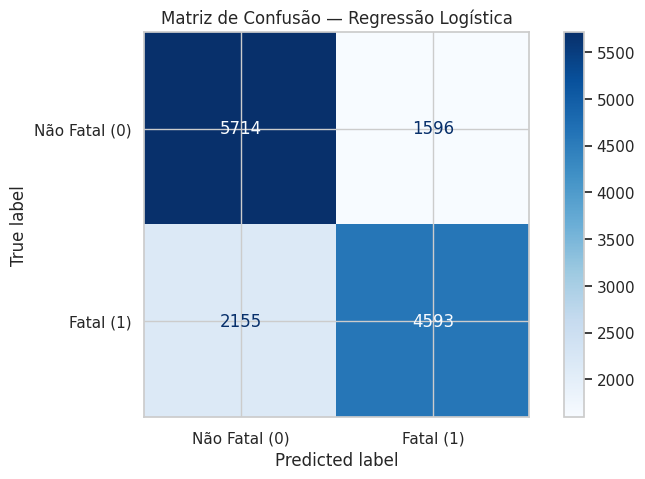

In [16]:
modelo_lr = LogisticRegression(max_iter=1000, random_state=SEED)
modelo_lr.fit(X_train, y_train)
avaliar("Regressão Logística", modelo_lr)

**Interpretação:** mesmo sendo o modelo mais simples, a Regressão Logística já tem um
desempenho respeitável, com **recall em torno de 0,68** na classe fatal e AUC de ~0,81. Pela
matriz de confusão, ainda há uma quantidade considerável de **falsos negativos** (acidentes
fatais previstos como não fatais), que é justamente o que mais queremos reduzir.

### 4.2 Árvore de Decisão

A Árvore de Decisão cria uma sequência de perguntas (por exemplo, "o tipo de acidente é
colisão frontal?") até chegar a uma decisão. Limitamos a profundidade (`max_depth=10`) para
evitar que ela "decore" os dados de treino (*overfitting*).

===== Árvore de Decisão =====
               precision    recall  f1-score   support

Não Fatal (0)       0.71      0.76      0.73      7310
    Fatal (1)       0.72      0.66      0.69      6748

     accuracy                           0.71     14058
    macro avg       0.71      0.71      0.71     14058
 weighted avg       0.71      0.71      0.71     14058

AUC-ROC: 0.7840


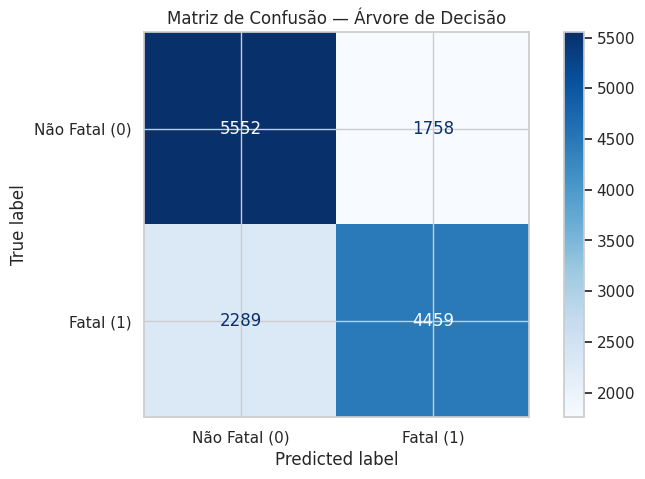

In [17]:
modelo_arvore = DecisionTreeClassifier(max_depth=10, random_state=SEED)
modelo_arvore.fit(X_train, y_train)
avaliar("Árvore de Decisão", modelo_arvore)

**Interpretação:** a Árvore de Decisão é a mais fácil de entender, mas aqui ela teve o
**pior desempenho** entre os modelos (recall e AUC mais baixos). Isso acontece porque uma única
árvore é "instável" e tende a errar mais do que um conjunto de árvores. Ela serve bem para
ilustrar o problema, mas mostra que precisamos de algo mais robusto.

### 4.3 Random Forest

O Random Forest treina **várias árvores** ao mesmo tempo, cada uma vendo uma parte diferente
dos dados, e depois combina as opiniões delas (uma espécie de "votação"). Isso costuma deixar o
resultado mais estável e preciso do que uma árvore sozinha.

===== Random Forest =====
               precision    recall  f1-score   support

Não Fatal (0)       0.73      0.79      0.76      7310
    Fatal (1)       0.75      0.68      0.71      6748

     accuracy                           0.73     14058
    macro avg       0.74      0.73      0.73     14058
 weighted avg       0.74      0.73      0.73     14058

AUC-ROC: 0.8110


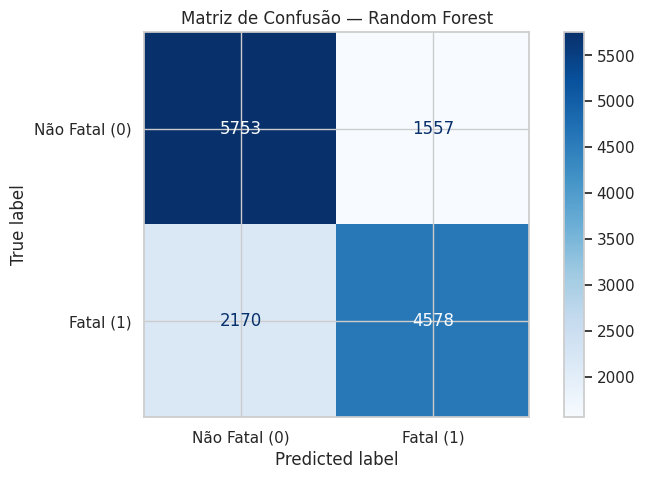

In [18]:
modelo_rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
modelo_rf.fit(X_train, y_train)
avaliar("Random Forest", modelo_rf)

**Interpretação:** como esperado, o Random Forest melhora em relação à árvore única e fica
**parecido com a Regressão Logística**, com bom equilíbrio entre as métricas. Ele é mais
robusto, mas no nosso caso ainda não foi o melhor — o que mostra que nem sempre o modelo mais
"pesado" vence por muito.

### 4.4 XGBoost

Por fim, o XGBoost. Diferente do Random Forest (que treina as árvores em paralelo), o boosting
cria as árvores **em sequência**, cada uma tentando corrigir os erros da anterior. É um dos
algoritmos mais fortes para dados em tabela como os nossos.

===== XGBoost =====
               precision    recall  f1-score   support

Não Fatal (0)       0.74      0.79      0.77      7310
    Fatal (1)       0.76      0.70      0.73      6748

     accuracy                           0.75     14058
    macro avg       0.75      0.75      0.75     14058
 weighted avg       0.75      0.75      0.75     14058

AUC-ROC: 0.8275


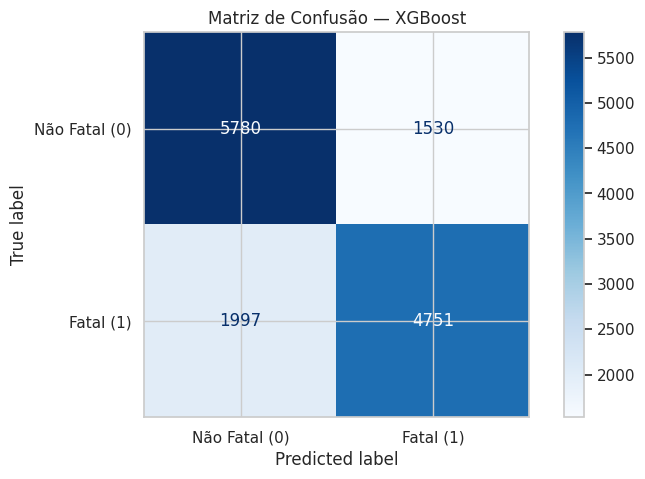

In [19]:
modelo_xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.06,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=SEED,
)
modelo_xgb.fit(X_train, y_train)
avaliar("XGBoost", modelo_xgb)

**Interpretação:** o XGBoost foi o **melhor modelo**, com o maior recall (~0,70), o maior F1
e a maior AUC-ROC. Ele consegue capturar melhor as combinações entre as variáveis categóricas
(por exemplo, "colisão frontal + plena noite") que, como vimos na análise exploratória, são as
mais ligadas à fatalidade. Mesmo assim, ainda sobram falsos negativos — vamos atacar esse ponto
na avaliação.

## 5. Avaliação

Nesta etapa comparamos todos os modelos lado a lado e analisamos os resultados com cuidado,
sempre com atenção especial ao **recall** da classe fatal.

### 5.1 Tabela comparativa dos modelos

In [20]:
# Ordenamos pela métrica que mais nos importa: o Recall
tabela_final = resultados.sort_values("Recall", ascending=False).reset_index(drop=True)
tabela_final.index = tabela_final.index + 1
tabela_final

,Modelo,Acurácia,Precisão,Recall,F1,AUC-ROC
1,XGBoost,0.7491,0.7564,0.7041,0.7293,0.8275
2,Regressão Logística,0.7332,0.7421,0.6806,0.7101,0.8145
3,Random Forest,0.7349,0.7462,0.6784,0.7107,0.811
4,Árvore de Decisão,0.7121,0.7172,0.6608,0.6879,0.784


**Interpretação:** o **XGBoost** lidera em praticamente todas as métricas, sendo o melhor em
Recall, F1 e AUC-ROC. Em seguida vêm, bem próximos, o Random Forest e a Regressão Logística, e
por último a Árvore de Decisão. Como a base está equilibrada, a acurácia também é confiável, e
ela acompanha a mesma ordem. Fica claro o ganho de usar um modelo de boosting.

### 5.2 Comparação visual das métricas

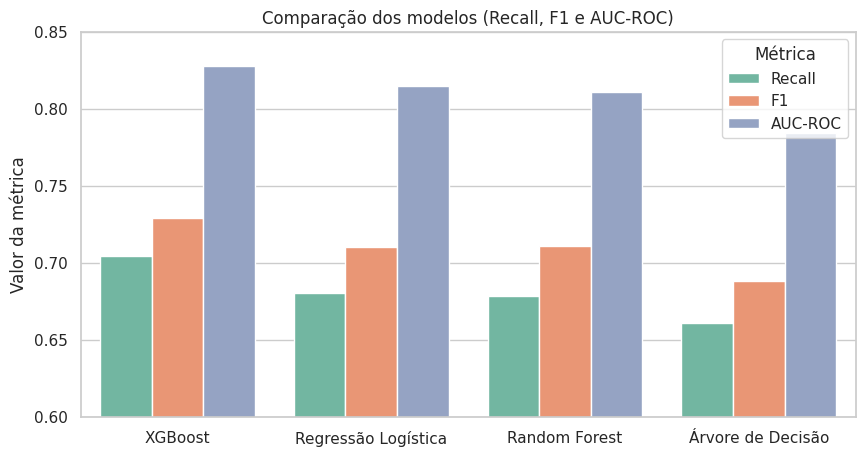

In [21]:
metricas_plot = tabela_final.melt(
    id_vars="Modelo", value_vars=["Recall", "F1", "AUC-ROC"],
    var_name="Métrica", value_name="Valor")

plt.figure(figsize=(10, 5))
sns.barplot(data=metricas_plot, x="Modelo", y="Valor", hue="Métrica", palette="Set2")
plt.title("Comparação dos modelos (Recall, F1 e AUC-ROC)")
plt.ylim(0.6, 0.85)
plt.xlabel("")
plt.ylabel("Valor da métrica")
plt.legend(title="Métrica")
plt.show()

**Interpretação:** o gráfico deixa visível que os quatro modelos têm desempenho parecido,
mas o XGBoost está sempre um pouco à frente. A diferença não é gigante, o que indica que o
**limite de desempenho está mais nos dados** (sinal relativamente fraco) do que na escolha do
algoritmo.

### 5.3 Curvas ROC

A curva ROC mostra a capacidade de cada modelo de **separar** as duas classes. Quanto mais a
curva se aproxima do canto superior esquerdo, melhor — e a linha pontilhada representa um
"chute" aleatório.

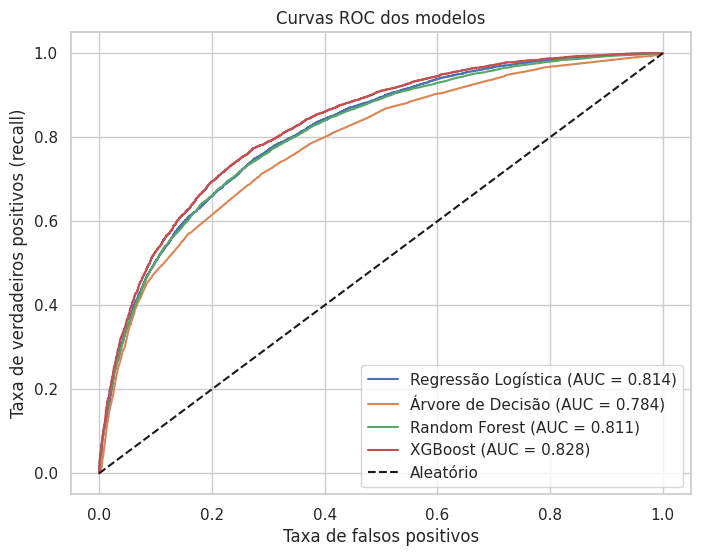

In [22]:
plt.figure(figsize=(8, 6))
modelos_treinados = {
    "Regressão Logística": modelo_lr,
    "Árvore de Decisão": modelo_arvore,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
}
for nome, modelo in modelos_treinados.items():
    proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Aleatório")
plt.title("Curvas ROC dos modelos")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos (recall)")
plt.legend()
plt.show()

**Interpretação:** todas as curvas ficam bem acima da diagonal (o que é bom), e a do
**XGBoost** é a que está mais "por cima", confirmando que ele é o melhor a distinguir acidentes
fatais dos não fatais.

### 5.4 Quais variáveis o modelo considera mais importantes?

O XGBoost consegue nos dizer quais colunas pesaram mais nas suas decisões. Isso é ótimo para
confirmar se o modelo "aprendeu" o que faz sentido na vida real.

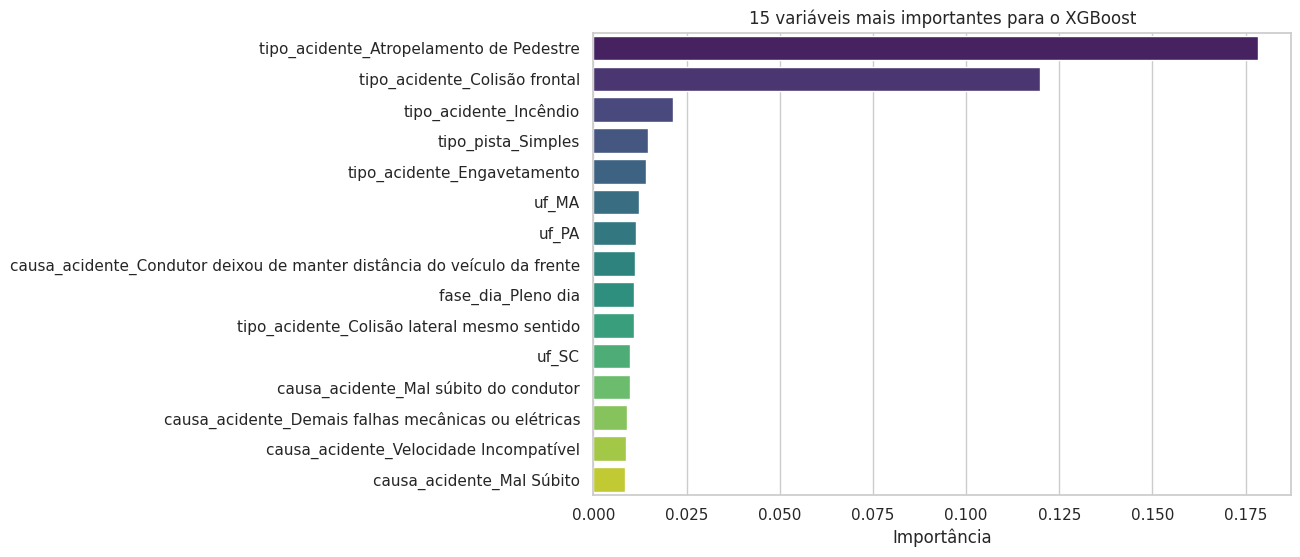

In [23]:
importancias = pd.Series(
    modelo_xgb.feature_importances_, index=X.columns
).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index,
            palette="viridis", legend=False)
plt.title("15 variáveis mais importantes para o XGBoost")
plt.xlabel("Importância")
plt.ylabel("")
plt.show()

**Interpretação:** as variáveis mais importantes são exatamente as que destacamos na análise
exploratória — ligadas ao **tipo de acidente** (atropelamento, colisão frontal) e à **causa**
(envolvendo pedestres). Ou seja, o modelo aprendeu padrões que **fazem sentido na realidade**,
o que aumenta a nossa confiança nele.

### 5.5 Ajustando o limiar para priorizar o Recall

Aqui voltamos ao nosso objetivo principal. Por padrão, os modelos consideram um acidente como
fatal quando a probabilidade prevista passa de **0,50**. Mas, como o nosso maior medo é
**deixar passar um acidente fatal** (falso negativo), podemos **baixar esse limiar**: assim o
modelo fica mais "desconfiado" e classifica mais acidentes como fatais, aumentando o recall.

O preço disso é gerar mais alarmes falsos (a precisão cai). Vamos testar alguns limiares no
XGBoost para encontrar um bom equilíbrio.

In [24]:
proba_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

linhas_limiar = []
for limiar in [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]:
    previsao = (proba_xgb >= limiar).astype(int)
    matriz = confusion_matrix(y_test, previsao)
    linhas_limiar.append({
        "Limiar": limiar,
        "Recall": round(recall_score(y_test, previsao), 3),
        "Precisão": round(precision_score(y_test, previsao), 3),
        "F1": round(f1_score(y_test, previsao), 3),
        "Falsos Negativos": matriz[1, 0],
    })

pd.DataFrame(linhas_limiar)

,Limiar,Recall,Precisão,F1,Falsos Negativos
0,0.50,0.704,0.756,0.729,1997
1,0.45,0.755,0.731,0.743,1653
2,0.40,0.799,0.701,0.747,1353
3,0.35,0.847,0.676,0.752,1034
4,0.30,0.885,0.646,0.747,778
5,0.25,0.921,0.615,0.737,533


**Interpretação:** repare como o **recall sobe** conforme baixamos o limiar. No limiar padrão
(0,50) o recall é ~0,70; ao baixar para **0,35**, ele sobe para **~0,85** e — o melhor — o F1
fica no seu ponto mais alto. Além disso, o número de **falsos negativos cai pela metade**. Esse
parece um ótimo ponto de equilíbrio para o nosso objetivo, então vamos adotá-lo.

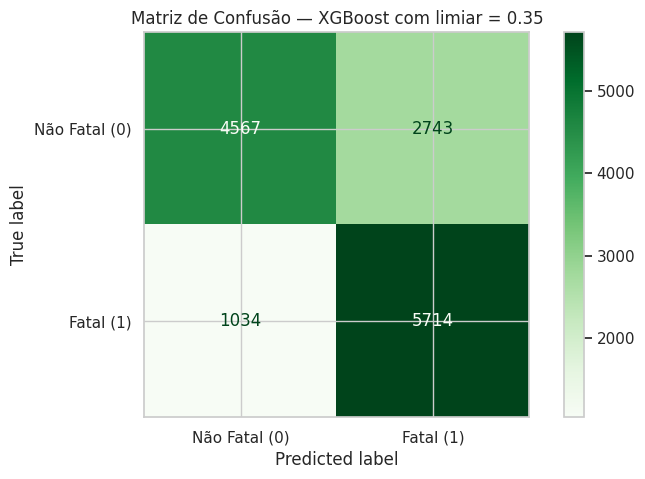

Recall:   0.847
Precisão: 0.676
F1:       0.752


In [25]:
LIMIAR_ESCOLHIDO = 0.35
previsao_ajustada = (proba_xgb >= LIMIAR_ESCOLHIDO).astype(int)

matriz = confusion_matrix(y_test, previsao_ajustada)
ConfusionMatrixDisplay(
    matriz, display_labels=["Não Fatal (0)", "Fatal (1)"]
).plot(cmap="Greens", values_format="d")
plt.title(f"Matriz de Confusão — XGBoost com limiar = {LIMIAR_ESCOLHIDO}")
plt.show()

print(f"Recall:   {recall_score(y_test, previsao_ajustada):.3f}")
print(f"Precisão: {precision_score(y_test, previsao_ajustada):.3f}")
print(f"F1:       {f1_score(y_test, previsao_ajustada):.3f}")

**Interpretação:** comparando esta matriz com a do XGBoost no limiar padrão, vemos que o
canto dos **falsos negativos diminuiu bastante** — ou seja, o modelo agora deixa passar muito
menos acidentes fatais, que era exatamente o nosso objetivo. Em troca, ele gera mais alarmes
falsos (classifica como fatais alguns acidentes que não foram), o que é um preço aceitável
quando o que está em jogo são vidas.

## 6. Discussão e Implantação

A etapa de *Implantação* do CRISP-DM não faz parte das entregas deste trabalho, mas vale
discutir **como o modelo poderia ser usado na prática**.

Um modelo como o nosso poderia apoiar os órgãos de trânsito a:
- **direcionar a fiscalização** para os trechos, horários e condições de maior risco de
  fatalidade;
- **planejar a alocação de equipes de resgate**, dando prioridade às ocorrências com maior
  probabilidade prevista de vítima fatal;
- **embasar políticas públicas** de segurança viária, com base nos fatores que o modelo
  apontou como mais associados à fatalidade.

**Limitações:** o desempenho é bom, mas não perfeito — o sinal nos dados é relativamente fraco,
e fatores que não estão na base (uso de cinto, velocidade real, condição do veículo) certamente
influenciam. Além disso, o modelo foi treinado em dados **balanceados** artificialmente, então,
para uso real, seria preciso recalibrá-lo para a proporção verdadeira de acidentes fatais.

## 7. Conclusão

Neste projeto aplicamos todas as etapas da metodologia **CRISP-DM** para prever se um acidente
de rodovia federal resulta em vítima fatal.

**O que alcançamos:**
- Fizemos a análise exploratória e descobrimos que o **tipo** e a **causa** do acidente, além
  da **fase do dia**, são os fatores mais ligados à fatalidade.
- Preparamos os dados com **engenharia de atributos** e **One-Hot Encoding**.
- Treinamos e comparamos **4 algoritmos**, sendo o **XGBoost** o melhor deles.
- Ajustamos o **limiar de decisão** para priorizar o **recall**, reduzindo de forma importante
  os falsos negativos — o erro mais grave no nosso problema.

**Objetivo alcançado?** Sim. Conseguimos um modelo que identifica a maioria dos acidentes
fatais (recall de ~0,85 após o ajuste de limiar) e que aprendeu padrões coerentes com a
realidade.

**Trabalhos futuros:** o ponto mais promissor seria **ampliar a base com mais variáveis**
(velocidade real, uso de cinto, condição do veículo), pois testamos outros modelos de boosting
da mesma família (LightGBM e CatBoost) e o desempenho ficou praticamente igual ao do XGBoost
(AUC entre 0,83 e 0,84) — ou seja, o limite atual parece estar mais nos **dados** do que na
escolha do algoritmo. Também seria possível fazer um ajuste mais fino dos hiperparâmetros para
tentar extrair um pouco mais de desempenho.